In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [98]:
df  = pd.read_csv("C:/Users/user/OneDrive/Desktop/Projects/Banking_Customer_Insights/Churn_Modelling.csv")

In [99]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


In [100]:
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,"96,270.64",0
9996,9997,15569892,Johnstone,516,France,Male,35,10,"57,369.61",1,1,1,"101,699.77",0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,"42,085.58",1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,"75,075.31",2,1,0,"92,888.52",1
9999,10000,15628319,Walker,792,France,Female,28,4,"130,142.79",1,1,0,"38,190.78",0


In [101]:
df.sample(10, random_state=42)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
6252,6253,15687492,Anderson,596,Germany,Male,32,3,"96,709.07",2,0,0,"41,788.37",0
4684,4685,15736963,Herring,623,France,Male,43,1,0.00,2,1,1,"146,379.30",0
1731,1732,15721730,Amechi,601,Spain,Female,44,4,0.00,2,1,0,"58,561.31",0
4742,4743,15762134,Liang,506,Germany,Male,59,8,"119,152.10",2,1,1,"170,679.74",0
4521,4522,15648898,Chuang,560,Spain,Female,27,7,"124,995.98",1,1,1,"114,669.79",0
6340,6341,15659064,Salas,790,Spain,Male,37,8,0.00,2,1,1,"149,418.41",0
576,577,15761986,Obialo,439,Spain,Female,32,3,"138,901.61",1,1,0,"75,685.97",0
5202,5203,15713354,Morrice,597,Germany,Female,22,6,"101,528.61",1,1,0,"70,529.00",1
6363,6364,15593454,Lambert,678,Spain,Female,40,4,"113,794.22",1,1,0,"16,618.76",0
439,440,15690134,Hughes,464,Germany,Female,42,3,"85,679.25",1,1,1,"164,104.74",0


In [102]:
df.shape

(10000, 14)

In [103]:
df.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [105]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00","5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00","15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
CreditScore,"10,000.00",650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,"10,000.00",38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00","76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,"10,000.00",0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,"10,000.00",0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,"10,000.00","100,090.24","57,510.49",11.58,"51,002.11","100,193.91","149,388.25","199,992.48"


In [106]:
df.describe(include="object").T

,count,unique,top,freq
Surname,10000,2932,Smith,32
Geography,10000,3,France,5014
Gender,10000,2,Male,5457


Business purpose: establish whether the dataset is suitable for customer segmentation and comparative analysis.

In [107]:
##Data quality profiling

In [108]:
##Check missing values

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
RowNumber,0,0.00
CustomerId,0,0.00
Surname,0,0.00
CreditScore,0,0.00
Geography,0,0.00
Gender,0,0.00
Age,0,0.00
Tenure,0,0.00
Balance,0,0.00
NumOfProducts,0,0.00


In [109]:
#Check duplicate records
print("Total records:", len(df))

print(
    "Duplicate complete records:",
    df.duplicated().sum()
)

print(
    "Unique customer IDs:",
    df["CustomerId"].nunique()
)

print(
    "Duplicate customer IDs:",
    df["CustomerId"].duplicated().sum()
)

Total records: 10000
Duplicate complete records: 0
Unique customer IDs: 10000
Duplicate customer IDs: 0


Business interpretation: If a customer appears multiple times, customer counts, balances and exit rates could be overstated.

In [110]:
#Check categorical consistency

categorical_columns = [
    "Geography",
    "Gender"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Geography
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender
Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [111]:
#Check the binary fields:
binary_columns = [
    "HasCrCard",
    "IsActiveMember",
    "Exited"
]

for col in binary_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


HasCrCard
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

IsActiveMember
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

Exited
Exited
0    7963
1    2037
Name: count, dtype: int64


In [112]:
#Check numerical ranges
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for col in numeric_columns:
    print(f"\n{col}")
    print(df[col].describe())


CreditScore
count   10,000.00
mean       650.53
std         96.65
min        350.00
25%        584.00
50%        652.00
75%        718.00
max        850.00
Name: CreditScore, dtype: float64

Age
count   10,000.00
mean        38.92
std         10.49
min         18.00
25%         32.00
50%         37.00
75%         44.00
max         92.00
Name: Age, dtype: float64

Tenure
count   10,000.00
mean         5.01
std          2.89
min          0.00
25%          3.00
50%          5.00
75%          7.00
max         10.00
Name: Tenure, dtype: float64

Balance
count    10,000.00
mean     76,485.89
std      62,397.41
min           0.00
25%           0.00
50%      97,198.54
75%     127,644.24
max     250,898.09
Name: Balance, dtype: float64

NumOfProducts
count   10,000.00
mean         1.53
std          0.58
min          1.00
25%          1.00
50%          1.00
75%          2.00
max          4.00
Name: NumOfProducts, dtype: float64

EstimatedSalary
count    10,000.00
mean    100,090.24
std      57,

In [113]:
#Investigate unusual values:
print("Negative balances:")
print((df["Balance"] < 0).sum())

print("Negative salaries:")
print((df["EstimatedSalary"] < 0).sum())

print("Invalid tenure:")
print((~df["Tenure"].between(0, 10)).sum())

print("Invalid product counts:")
print((~df["NumOfProducts"].between(1, 4)).sum())

Negative balances:
0
Negative salaries:
0
Invalid tenure:
0
Invalid product counts:
0


Important: A balance of zero is not necessarily missing data. It could mean that the customer has no funds in the account at the observation date.

Likewise, a low salary or a high age should not automatically be treated as an error.

**Exploratory data analysis (EDA)**

Understand customer exit distribution

In [114]:
exit_counts = df["Exited"].value_counts()

print(exit_counts)

Exited
0    7963
1    2037
Name: count, dtype: int64


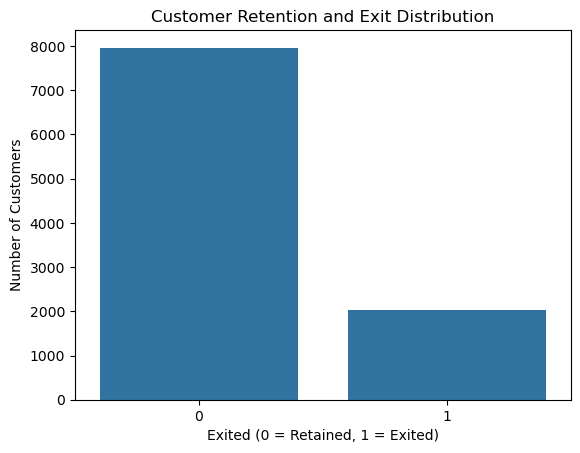

In [115]:
sns.countplot(
    data=df,
    x="Exited"
)

plt.title("Customer Retention and Exit Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Exited)")
plt.ylabel("Number of Customers")
plt.show()

In [116]:
#Exit Rate

In [117]:
exit_rate = df["Exited"].mean() * 100

print(f"Customer exit rate: {exit_rate:.2f}%")

Customer exit rate: 20.37%


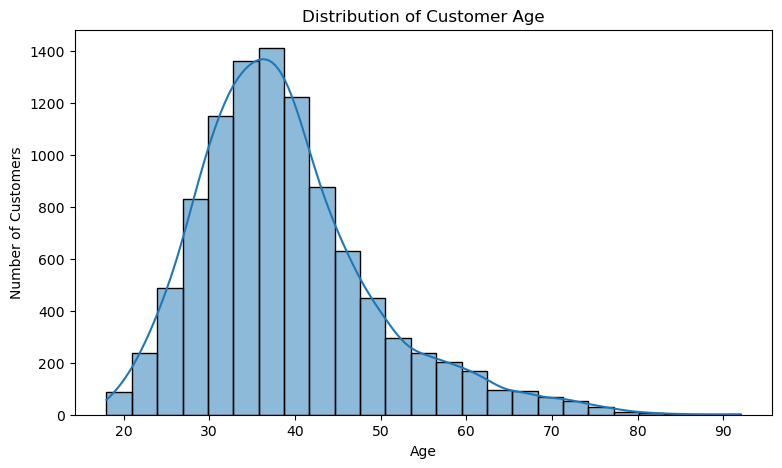

In [118]:
#Analyse customer age distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=25,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

Business question: Which age groups make up the bank's customer base?

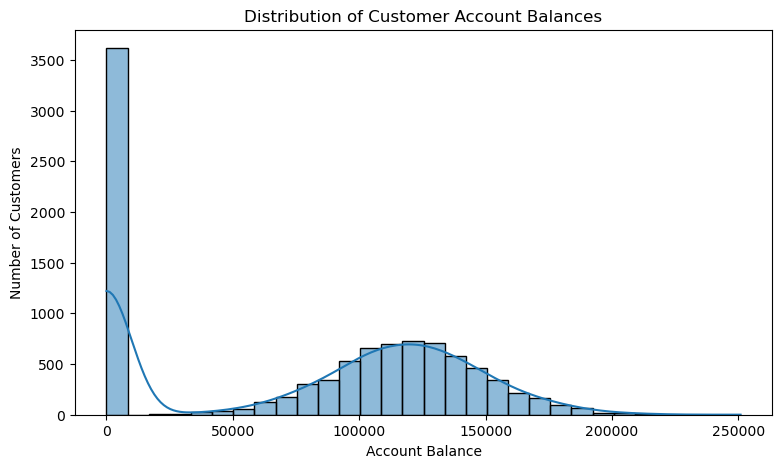

In [119]:
#Analyse account balances
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Balance",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Account Balances")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")
plt.show()

In [120]:
#Investigate zero balances:
zero_balance = (df["Balance"] == 0).sum()

print("Customers with zero balance:", zero_balance)

print(
    "Percentage with zero balance:",
    zero_balance / len(df) * 100
)

Customers with zero balance: 3617
Percentage with zero balance: 36.17


Business question: How much of the customer base has a zero account balance, and how is the balance distributed among customers?

In [121]:
#Examine product adoption
product_counts = df["NumOfProducts"].value_counts().sort_index()

print(product_counts)

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64


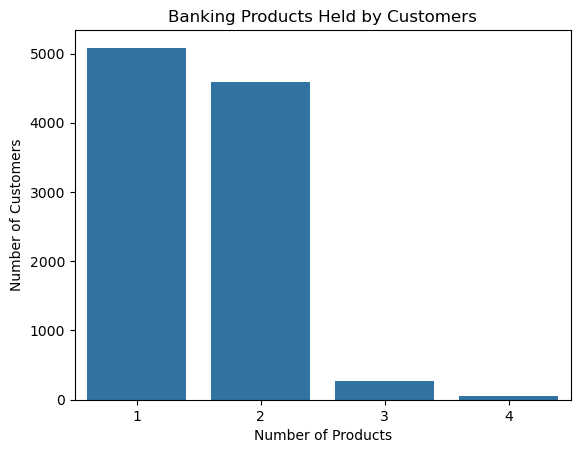

In [122]:
sns.countplot(
    data=df,
    x="NumOfProducts"
)

plt.title("Banking Products Held by Customers")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")
plt.show()

Business question: Does the bank have a customer base concentrated around one product, or are customers using multiple products?

In [123]:
#Compare exit rates by customer characteristics
def exit_rate_by(column):

    result = (
        df.groupby(column)["Exited"]
        .agg(
            Customers="count",
            Exited_Customers="sum",
            Exit_Rate="mean"
        )
        .reset_index()
    )

    result["Exit_Rate"] *= 100

    return result.sort_values(
        "Exit_Rate",
        ascending=False
    )

In [124]:
#Test it:
exit_rate_by("Geography")
exit_rate_by("Gender")
exit_rate_by("IsActiveMember")
exit_rate_by("NumOfProducts")




,NumOfProducts,Customers,Exited_Customers,Exit_Rate
3,4,60,60,100.00
2,3,266,220,82.71
0,1,5084,1409,27.71
1,2,4590,348,7.58


In [125]:
#Clean the dataset
#After profiling, we can prepare the data for modelling.

In [126]:
df_clean = df.drop(
    columns=["RowNumber", "Surname"]
).copy()

In [127]:
#Standardise categorical values
df_clean["Geography"] = (
    df_clean["Geography"]
    .astype("string")
    .str.strip()
)

df_clean["Gender"] = (
    df_clean["Gender"]
    .astype("string")
    .str.strip()
    .str.title()
)


In [128]:
#Validate binary fields
for col in ["HasCrCard", "IsActiveMember", "Exited"]:

    print(
        col,
        df_clean[col].unique()
    )

HasCrCard [1 0]
IsActiveMember [1 0]
Exited [1 0]


In [129]:
#Feature engineering
#Age groups
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "Above 65"
    ]
)

Business use: compare customer balances, product adoption and exit rates by age group.

Tenure groups

In [130]:
df_clean["Tenure_Group"] = pd.cut(
    df_clean["Tenure"],
    bins=[-1, 2, 5, 8, 10],
    labels=[
        "New Customers (0-2 Years)",
        "Developing (3-5 Years)",
        "Established (6-8 Years)",
        "Long-standing (9-10 Years)"
    ]
)

Business use: investigate whether customers with longer banking relationships exhibit different product adoption and exit patterns.

In [131]:
df_clean["Balance"].describe(
    percentiles=[0.25, 0.50, 0.75]
)

count    10,000.00
mean     76,485.89
std      62,397.41
min           0.00
25%           0.00
50%      97,198.54
75%     127,644.24
max     250,898.09
Name: Balance, dtype: float64

In [132]:
# Separate zero-balance customers from positive-balance customers

df_clean["Balance_Segment"] = "Zero Balance"

positive_balance = df_clean["Balance"] > 0

df_clean.loc[
    positive_balance,
    "Balance_Segment"
] = pd.qcut(
    df_clean.loc[positive_balance, "Balance"],
    q=4,
    labels=[
        "Lower Balance",
        "Mid-Lower Balance",
        "Mid-Upper Balance",
        "Higher Balance"
    ]
).astype(str)

print(df_clean["Balance_Segment"].value_counts())

Balance_Segment
Zero Balance         3617
Lower Balance        1596
Higher Balance       1596
Mid-Lower Balance    1596
Mid-Upper Balance    1595
Name: count, dtype: int64


In [133]:
#Product adoption segments
df_clean["Product_Segment"] = np.select(
    [
        df_clean["NumOfProducts"] == 1,
        df_clean["NumOfProducts"] == 2,
        df_clean["NumOfProducts"] >= 3
    ],
    [
        "Single Product",
        "Two Products",
        "Three or More Products"
    ],
    default="Unclassified"
)

In [134]:
#Customer engagement segments
df_clean["Engagement_Status"] = np.where(
    df_clean["IsActiveMember"] == 1,
    "Active",
    "Inactive"
)

In [135]:
#Create a readable exit status
df_clean["Customer_Status"] = np.where(
    df_clean["Exited"] == 1,
    "Exited",
    "Retained"
)

#This makes the data easier to use in SQL and Power BI.

In [136]:
#Validate the engineered dataset
print("Final rows:", len(df_clean))

print(
    "Unique customer IDs:",
    df_clean["CustomerId"].nunique()
)

print(
    "Duplicate customer IDs:",
    df_clean["CustomerId"].duplicated().sum()
)

print(
    "Missing values:",
    df_clean.isnull().sum().sum()
)

print(
    "Exit rate:",
    df_clean["Exited"].mean() * 100
)

Final rows: 10000
Unique customer IDs: 10000
Duplicate customer IDs: 0
Missing values: 0
Exit rate: 20.369999999999997


In [137]:
#Inspect the newly created fields:
new_features = [
    "Age_Group",
    "Tenure_Group",
    "Balance_Segment",
    "Product_Segment",
    "Engagement_Status",
    "Customer_Status"
]

for col in new_features:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


Age_Group
Age_Group
36-45       3736
26-35       3542
46-55       1311
18-25        611
56-65        536
Above 65     264
Name: count, dtype: int64

Tenure_Group
Tenure_Group
Established (6-8 Years)       3020
Developing (3-5 Years)        3010
New Customers (0-2 Years)     2496
Long-standing (9-10 Years)    1474
Name: count, dtype: int64

Balance_Segment
Balance_Segment
Zero Balance         3617
Lower Balance        1596
Higher Balance       1596
Mid-Lower Balance    1596
Mid-Upper Balance    1595
Name: count, dtype: int64

Product_Segment
Product_Segment
Single Product            5084
Two Products              4590
Three or More Products     326
Name: count, dtype: int64

Engagement_Status
Engagement_Status
Active      5151
Inactive    4849
Name: count, dtype: int64

Customer_Status
Customer_Status
Retained    7963
Exited      2037
Name: count, dtype: int64


In [138]:
#Check that the data has retained the same number of customer records:
assert len(df_clean) == len(df)

assert df_clean["CustomerId"].is_unique

assert df_clean["Exited"].isin([0, 1]).all()

assert df_clean["Age"].between(18, 92).all()

assert df_clean["Tenure"].between(0, 10).all()

print("Validation completed.")

Validation completed.


In [142]:
#Export the processed dataset
df_clean.to_csv("C:/Users/user/OneDrive/Desktop/Projects/Banking_Customer_Insights/banking_customer_clean.csv",
    index=False
)

In [144]:
from pathlib import Path

# Create the processed data directory if it does not exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Export customer segment summary
customer_summary.to_csv(
    processed_dir / "customer_segment_summary.csv",
    index=False
)

print("Customer segment summary exported successfully.")

Customer segment summary exported successfully.
